# ICCS205 — Numerical Computation
# Midterm Examination — Trimester 3 / 2025

**Time allowed: 2 hours**  |  **Total: 80 marks**

---

### Instructions

* This is a **single Jupyter notebook** exam. You will answer **all** questions inside this notebook and submit this `.ipynb` file at the end.
* There are **6 questions**:
  * **Q1–Q2 are written questions (10 marks each = 20).** Type your answer in the **markdown** cell provided under each question (double-click the cell to edit, then run it to render). No long essays — be clear and to the point.
  * **Q3–Q6 are coding questions (15 marks each = 60).** Write and **run** your code in the **code** cell provided. You may add extra cells if you need them.
* A **toolkit** of ready-made numerical-methods functions is provided in the cell below (bisection, Newton–Raphson, finite differences, trapezoid, Simpson, Lagrange interpolation, Gaussian elimination, linear regression). **You may use these freely**, or write your own.
* You may use `numpy`, `matplotlib`, and `math`. You may **not** use library functions that solve the whole problem for you (e.g. `scipy.optimize`, `numpy.polyfit`, `numpy.linalg.solve`) unless a question explicitly allows it.
* Show your reasoning. For coding questions, **print your final answers** and label plots so they can be graded.
* Make sure every cell **runs without errors** before you submit (`Kernel → Restart & Run All`).

> **Tip on time:** roughly 30 minutes for the two written questions and the rest for the four coding questions. Don't get stuck — move on and come back.


## Q1 — Root finding (written, 10 marks)

An engineer models the equilibrium operating point of a device as the **root** of

$$ f(x) = x^3 - 2x - 5. $$

The plot below shows $f(x)$; it has a single real root a little above $x = 2$. The engineer is deciding between the **bisection method** and the **Newton–Raphson method**.

<img src="q1.png" width="640"/>

Answer the following (no calculation needed):

1. What information must you supply to *start* each method?
2. Compare their **convergence**: which is guaranteed to find the root, and which is faster? Roughly how fast is each?
3. Give one **advantage and one disadvantage** of each method. When could Newton–Raphson **fail**?
4. For *this particular* $f(x)$, which method would you choose, and why? (You may suggest combining them.)

*Keep your answer concise.*

1. What information must you supply to *start* each method?
> both method needs a function to start with, as well as tolerance and maximum iteration (so the code doesn't stuck in infinite loop). uniquely, upper and lower bound for bisection method; any arbitrary point for Newton-Raphson method, preferably somewhere close to the root already (tho the algorithm converges fairly fast already). we might also want to check that the function is continuous for the entire range in order for the intermediate value theorem (IVT) to work (for bisection method). 

2. Compare their **convergence**: which is guaranteed to find the root, and which is faster? Roughly how fast is each?
> we're guaranteed to find root with bisection method, while for Newton-Raphson method, the result could diverges or oscillate if our initial guess is bad: derivative is zero, bad luck or point near local minimum/ maximum. 
> 
> as for the convergence speed
>
> - bisection method: linear convergence, around $\frac{\text{initial bracket size}}{2^{n + 1}}$ where $n$ is the number of iteration, in case we pick the middle point of our final bracket. we could calculate the expected tolerance to number of iteration easily, as it just a factor of $\frac12$, for double precision float, rough estimation (upper bound for maximum iteration) should be `max_iter = 52 + int(np.ceil(np.log2(right - left)))` where 52 is just the mantissa of IEEE 754 double precision float. 
>
> - Newton-Raphson method: quadratic convergence, converges much faster (with chance of failing), convergence speed depends on how steep the function's slope is around it's root. 

3. Give one **advantage and one disadvantage** of each method. When could Newton–Raphson **fail**?
> bisection method is slow but robust (always converges, always give correct root result); while Newton-Raphson method converges quickly, but we have to be careful when picking the intial pint, and still convergence is not guaranteed.

4. For *this particular* $f(x)$, which method would you choose, and why? (You may suggest combining them.)
> I'd just do both, the function is quite simple and from surface (rough) inspection (manually), I don't think Newton-Raphson method will fail. do both until we reach our desired tolerance, the compare the result of both method, it should be close. but if you want a single method, I'd choose Newton-Raphson method. 

## ✍️ Fill in your details

- **Name:** Jiraroj Wiruchpongsanon
- **Student ID:** 6781617


In [1]:
# ============================================================
# PROVIDED TOOLKIT  — run this cell first.
# You may use any of these functions in your answers, or write your own.
# ============================================================
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import math


def bisection(f, a, b, tol=1e-10, max_iter=200):
    """Find a root of f in [a, b] by bisection. Requires f(a)*f(b) < 0."""
    if f(a) * f(b) > 0:
        raise ValueError("f(a) and f(b) must have opposite signs (no sign change).")
    for _ in range(max_iter):
        c = 0.5 * (a + b)
        if abs(f(c)) < tol or 0.5 * (b - a) < tol:
            return c
        if f(a) * f(c) < 0:
            b = c
        else:
            a = c
    return 0.5 * (a + b)


def newton_raphson(f, df, x0, tol=1e-10, max_iter=100):
    """Find a root of f near x0 using Newton-Raphson. df is the derivative of f."""
    x = x0
    for _ in range(max_iter):
        fx = f(x)
        if abs(fx) < tol:
            return x
        x = x - fx / df(x)
    return x


def central_difference(f, x, h=1e-5):
    """Approximate f'(x) using the central finite difference (error O(h^2))."""
    return (f(x + h) - f(x - h)) / (2 * h)


def trapezoid(f, a, b, n):
    """Approximate the integral of f from a to b using n subintervals (trapezoid rule)."""
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])


def simpson(f, a, b, n):
    """Approximate the integral of f from a to b using Simpson's rule (n must be even)."""
    if n % 2 == 1:
        n += 1  # Simpson needs an even number of subintervals
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return (h / 3) * (y[0] + y[-1] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2]))


def lagrange_interpolating_polynomial(x_points, y_points):
    """Return a function L(x) that evaluates the Lagrange polynomial through the data."""
    x_points = np.asarray(x_points, dtype=float)
    y_points = np.asarray(y_points, dtype=float)

    def L(x):
        x = np.asarray(x, dtype=float)
        total = np.zeros_like(x, dtype=float)
        n = len(x_points)
        for i in range(n):
            term = np.ones_like(x) * y_points[i]
            for j in range(n):
                if j != i:
                    term = term * (x - x_points[j]) / (x_points[i] - x_points[j])
            total = total + term
        return total

    return L


def gaussian_elimination(A, b):
    """Solve A x = b using Gaussian elimination with partial pivoting."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    for i in range(n):
        # Partial pivoting: swap in the row with the largest pivot.
        p = np.argmax(np.abs(A[i:, i])) + i
        if p != i:
            A[[i, p]] = A[[p, i]]
            b[[i, p]] = b[[p, i]]
        for k in range(i + 1, n):
            factor = A[k, i] / A[i, i]
            A[k, i:] -= factor * A[i, i:]
            b[k] -= factor * b[i]
    # Back substitution.
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - np.dot(A[i, i + 1:], x[i + 1:])) / A[i, i]
    return x


def linear_regression(x, y):
    """Least-squares best-fit line y = m*x + c. Returns (m, c)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    m = (n * np.sum(x * y) - np.sum(x) * np.sum(y)) / (n * np.sum(x ** 2) - np.sum(x) ** 2)
    c = (np.sum(y) - m * np.sum(x)) / n
    return m, c


print("Toolkit loaded: bisection, newton_raphson, central_difference, trapezoid,")
print("                simpson, lagrange_interpolating_polynomial,")
print("                gaussian_elimination, linear_regression")


Toolkit loaded: bisection, newton_raphson, central_difference, trapezoid,
                simpson, lagrange_interpolating_polynomial,
                gaussian_elimination, linear_regression


---

**Your answer:**

*(Double-click this cell to write your answer, then run it.)*

Okay? 

- **Name:** Jiraroj Wiruchpongsanon
- **Student ID:** 6781617

---

## Q2 — Integrating measured data (written, 10 marks)

A solar panel's power output $P(t)$ (in kilowatts) is **measured once per hour** over a day. The measurements are shown below. The engineer wants the **total energy** produced (in kilowatt-hours), which is the **area under the curve** $\int P(t)\,dt$.

<img src="q2.png" width="640"/>

Answer the following (no calculation needed):

1. The data are **discrete points**, not a continuous function. How do you turn them into an area estimate? Name a numerical method you would use.
2. The output is known to vary **smoothly** during the day. How can you use that to get a **more accurate** estimate? (Compare the trapezoid rule and Simpson's rule.)
3. How does the **spacing** of the measurements (e.g. once per hour vs once per 5 minutes) affect the accuracy?
4. The measurements contain some random **noise**. How does noise affect your estimate of the total energy, and is the total more or less sensitive to noise than, say, an individual derivative would be?

*Keep your answer concise.*


**Your answer:**

*(Double-click this cell to write your answer, then run it.)*
1. The data are **discrete points**, not a continuous function. How do you turn them into an area estimate? Name a numerical method you would use.
> integration could be think of area under the function's plot above some axis. we're give data points (above the axis), so we 'integrate' over them. I'd use the Trapezoid rule for this one, by splitting the x-axis into 23 sections (by hour), we then think of each section as a trapezoid of 1 hour width and heigh of $x_i$ and $x_{i+1}$ where $i \in \{0, 23\}$, and just sum those trapezoid area up to get area under curve of time (hours) vs. power (kW). 

2. The output is known to vary **smoothly** during the day. How can you use that to get a **more accurate** estimate? (Compare the trapezoid rule and Simpson's rule.)
> In this case, use Simpson's rule instead. It works by having the interaction between points as a parabola (3 points: $f(x_i)$, $f(\frac{x_i + x_{i+1}}{2}) and $f(x_{i+1})$) instead of a line of trapezoid. In short, the upper part of the estimated are could curve, so it's more accurate than a straight line, and the quadratic of integral is fairly easy to find as well (not as easy as trapezoid area).

3. How does the **spacing** of the measurements (e.g. once per hour vs once per 5 minutes) affect the accuracy?
> I don't think it'd gain much accuracy if any, in this case, if we're using Simpson's rule already. We only got data points by hour, so the rest is just interpolating points as a straight line (according to the given plot image) or with quadratic.
>
> But, if the measurements is done physically every 5 minutes compare that to once every hour, instead of interpolate the one hour result, then we should gain significant accuracy point as Simpson's rule converges by $\Theta(n^{-4})$, those additional data points (12 times more dense) would effect the result.

4. The measurements contain some random **noise**. How does noise affect your estimate of the total energy, and is the total more or less sensitive to noise than, say, an individual derivative would be?
> In this case, the total energy is compute by integration, which usually works well with minor random noise, assuming the noise is uniformly distributed (like in well-tested digital RNG function). So, the mean of those noise should cancles out and the result of the integral should be minimally affected by those noises. Meanwhile, derivative usually is more sensitive to noises, especially when the datapoints are densely packed in a small range. 

---

## Q3 — Solving a linear system (coding, 15 marks)

A chemical plant blends three liquid feedstocks **A**, **B**, and **C** to make a coolant. Mixing $x_A$, $x_B$, $x_C$ litres of each must hit **exact** target amounts of three additives. The balances give the linear system

$$
\begin{aligned}
2x_A + 1x_B + 1x_C &= 8 \\
1x_A + 3x_B + 2x_C &= 13 \\
1x_A + 1x_B + 4x_C &= 9
\end{aligned}
$$

**Tasks**

1. Write the system in matrix form $A\mathbf{x} = \mathbf{b}$: define the matrix `A` and vector `b` in code.
2. Solve for $\mathbf{x}$ (the litres of A, B, C) using **Gaussian elimination** (`gaussian_elimination` in the toolkit). Print the amount of each feedstock.
3. **Verify** your answer: compute $A\mathbf{x}$ and compare it to $\mathbf{b}$ (report the largest residual). Is the solution physically sensible (all amounts non-negative)?


In [2]:
# Q3: define your matrix A and vector b for the system, then solve.
A = [[2, 1, 1], [1, 3, 2], [1, 1, 4]]
b = [8, 13, 9]
print(A)
print(b)

[[2, 1, 1], [1, 3, 2], [1, 1, 4]]
[8, 13, 9]


In [3]:
# Write your solution here.
x = gaussian_elimination(A, b)
x

array([2., 3., 1.])

In [4]:
np.max((np.asarray(A) @ np.asarray(x)) - np.asarray(b))     # @ or np.matmul() for matrix multiplication

np.float64(0.0)

---

## Q4 — From samples to arrival time (coding, 15 marks) — *mixed methods*

During a 10-second test, a car's speed is recorded by GPS at only a **few** time instants. The speed varies smoothly and is always positive. The samples are provided in the setup cell as `t_data` (seconds) and `v_data` (metres per second).

This question deliberately **combines three techniques** you have learned: **interpolation**, **integration**, and **root finding**.

**Tasks**

1. **Interpolation.** The speed was sampled at only a few times. Build a *continuous* speed model $v(t)$ from the samples using **Lagrange interpolation** (`lagrange_interpolating_polynomial`). Plot the samples together with the interpolating curve.
2. **Integration.** The distance travelled up to time $t$ is $s(t) = \int_0^t v(\tau)\,d\tau$. Using **numerical integration** of your speed model, compute the **total distance** $D = s(10)$ travelled over the full 10 seconds.
3. **Root finding.** Find the time $t^\star$ at which the car has travelled exactly **half** of the total distance. *(Hint: $t^\star$ solves $s(t^\star) - D/2 = 0$ — combine your integrator with a root-finding method.)* Print $t^\star$ and verify that $s(t^\star)\approx D/2$.


we know that

$$\int_0^t \frac{dv(t)}{dt} = s(t)$$

In [5]:
# Q4 data (run this cell; do not modify)
t_data = np.array([0.0, 2.0, 4.0, 6.0, 8.0, 10.0])    # time samples (seconds)
v_data = np.array([0.0, 9.0, 15.0, 19.0, 21.0, 22.0])  # speed samples (m/s), smooth & positive


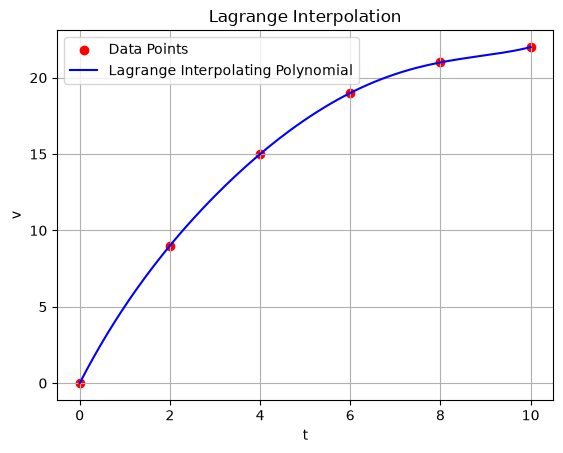

D:  151.66666666666669
half:  6.385651693490217
s(half):  75.83333333426445
2 * s(half):  151.6666666685289
residual:  -9.311094117947505e-10


In [6]:
# Write your solution here.

# 1. **Interpolation.** The speed was sampled at only a few times. Build a *continuous* speed model $v(t)$ from the samples using **Lagrange interpolation** 
# (`lagrange_interpolating_polynomial`). Plot the samples together with the interpolating curve.

lagrange = lagrange_interpolating_polynomial(t_data, v_data)

x_dense = np.linspace(0, 10, 1 << 7)
y_dense = lagrange(x_dense)

plt.scatter(t_data, v_data, label='Data Points', color='red')
plt.plot(x_dense, y_dense, label='Lagrange Interpolating Polynomial', color='blue')
plt.xlabel('t')
plt.ylabel('v')
plt.title('Lagrange Interpolation')
plt.legend()
plt.grid(True)
plt.show()


# 2. **Integration.** The distance travelled up to time $t$ is $s(t) = \int_0^t v(\tau)\,d\tau$. Using **numerical integration** of your speed model, 
# compute the **total distance** $D = s(10)$ travelled over the full 10 seconds.

def s(t) -> float: 
    return simpson(lagrange, 0, t, 1 << 6)

D = s(10)
print("D: ", D)

# 3. **Root finding.** Find the time $t^\star$ at which the car has travelled exactly **half** of the total distance. 
# *(Hint: $t^\star$ solves $s(t^\star) - D/2 = 0$ — combine your integrator with a root-finding method.)* Print $t^\star$ and verify that $s(t^\star)\approx D/2$.

def f4(x) -> float:
    return s(x) - D/2

# the bound must be somewhere inside (0, 10) for sure
half = bisection(f4, 0, 10)
print("half: ", half)
print("s(half): ", s(half))
print("2 * s(half): ", 2 * s(half))
print("residual: ", D/2 - s(half))


---

## Q5 — Finding an energy level by "shooting" (coding, 15 marks)

In physics, a particle trapped in a box can only have certain **allowed energies**, called **eigen-energies**. Finding them is the heart of solving the **Schrödinger equation**. *You do not need to know any quantum mechanics for this question* — it reduces to **an integral plus a search over the energy**.

A particle is trapped in a box between $x = 0$ and $x = 1$. Inside the box there is a potential $V(x) = 4x$ (provided in the setup cell). In simplified units, a quantization rule says the allowed energies $E$ are exactly the values for which

$$ g(E) \;=\; \int_0^1 \sqrt{\,E - V(x)\,}\; dx \;=\; (n+1)\,\pi, \qquad n = 0, 1, 2, \dots $$

Here $n$ labels the level: $n=0$ is the lowest energy (the **ground state**), $n=1$ is the next one, and so on. (For the square root to stay real we need $E > V(x)$ everywhere in the box, i.e. $E > 4$.)

The **"shooting" idea**: pick a trial energy $E$, compute the integral $g(E)$, and adjust $E$ until $g(E)$ hits the target. The energy that makes it match is the eigen-energy. So this is **numerical integration** (to get $g(E)$) **combined with root finding** (to hit the target).

**Tasks**

1. Write a function `g(E)` that computes $\displaystyle\int_0^1 \sqrt{E - V(x)}\,dx$ using **numerical integration** (trapezoid or Simpson from the toolkit), with $V(x)=4x$.
2. Find the **ground-state** energy ($n=0$): the value of $E$ for which $g(E) = \pi$. Do it with a **root-finding** method applied to $F(E) = g(E) - \pi$. Print the energy.
3. Find the **first excited** energy ($n=1$, target $2\pi$) in the same way. Print it and confirm it is **larger** than the ground-state energy.

*(Optional: plot $g(E)$ against $E$ and mark the target levels $\pi$ and $2\pi$.)*


In [7]:
# Q5: the potential inside the box (0 <= x <= 1)
def V(x):
    return 4 * x      # a simple "tilted box" potential


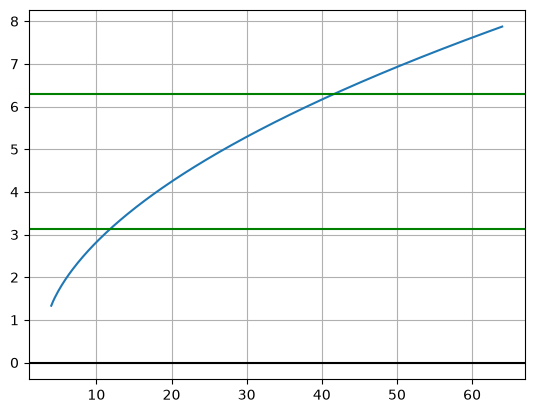

11.903494907310233
41.48686284432188


In [8]:
# Write your solution here.

# 1. Write a function `g(E)` that computes $\displaystyle\int_0^1 \sqrt{E - V(x)}\,dx$ using **numerical integration** (trapezoid or Simpson from the toolkit), with $V(x)=4x$.
def g(E):
    def f(x):
        return np.sqrt(E - V(x))
        
    return simpson(f, 0, 1, 1 << 8)

# E > 4
x = np.linspace(4, 1 << 6, 1 << 8)
y = np.array([g(E) for E in x])

plt.plot(x, y)
plt.axhline(0, color='black')
plt.axhline(np.pi, color='green')
plt.axhline(2 * np.pi, color='green')
plt.grid(True)
plt.show()

def F5_1(E):
    return g(E) - np.pi

# this gives the bound of around (10, 20)
'''
# E > 4
x = np.linspace(4, 1 << 4, 1 << 4)
y = np.array([F(E) for E in x])

plt.plot(u, y)
plt.axhline(0, color='black')
plt.grid(True)
plt.show()
'''

energy0 = bisection(F5_1, 10, 20)
print(energy0)
# print(abs(np.pi - g(energy0)))

# 3. Find the **first excited** energy ($n=1$, target $2\pi$) in the same way. Print it and confirm it is **larger** than the ground-state energy.
def F5_2(E):
    return g(E) - 2 * np.pi

energy1 = bisection(F5_2, 40, 50)
print(energy1)

---

## Q6 — Gradient descent (coding, 15 marks)

Find the minimum of the function

$$ f(x, y) = (x - 3)^2 + 2\,(y + 1)^2 $$

using **gradient descent** (do **not** just read off the answer — implement the iteration).

The gradient is
$$ \nabla f = \big(\,2(x-3),\; 4(y+1)\,\big). $$

**Tasks**

1. Implement gradient descent starting from $(x_0, y_0) = (0, 0)$. Choose a sensible **learning rate** and a stopping criterion (e.g. stop when the gradient's magnitude is below a small tolerance, or after a maximum number of iterations).
2. Print the **minimum point** $(x^*, y^*)$ you find, the value $f(x^*, y^*)$, and the number of iterations used. (The true minimum is at $(3, -1)$.)
3. **Plot** how $f$ decreases versus iteration number (a convergence curve).
4. Briefly (1–2 sentences, in a comment or markdown) say what happens if the learning rate is chosen **too large**.


[ 3. -1.]
minimum point: ( 2.999999996890986 ,  -0.9999999999999987 )
f(x*, y*):  9.66596764919347e-18
iterations used:  1024


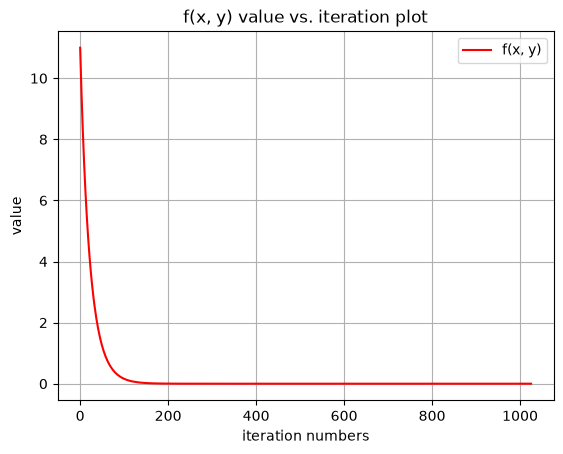

In [9]:
# Q6 function and its gradient
def f(x, y):
    return (x - 3) ** 2 + 2 * (y + 1) ** 2

def grad_f(x, y):
    return np.array([2 * (x - 3), 4 * (y + 1)])

# 1. Implement gradient descent starting from $(x_0, y_0) = (0, 0)$. 
# Choose a sensible **learning rate** and a stopping criterion 
# (e.g. stop when the gradient's magnitude is below a small tolerance, or after a maximum number of iterations).

def gradient_descent(grad_f, start, alpha, n_iter):
    """
    Performs gradient descent to find the minimum of a function.
    
    Args:
        grad_f: A function that computes the gradient.
        start: The starting point (x, y).
        alpha: The learning rate.
        n_iter: The number of iterations.
        
    Returns:
        A list of points visited during the descent.
    """
    path = [start]
    x = np.array(start)
    for _ in range(n_iter):
        grad = grad_f(x[0], x[1])
        x = x - alpha * grad
        path.append(x)
    return np.array(path)

start = np.asarray([0, 0])
alpha = 0.01
n_iter = 1 << 10

path = gradient_descent(grad_f, start, alpha, n_iter)
print(path[-1])

# 2. Print the **minimum point** $(x^*, y^*)$ you find, the value $f(x^*, y^*)$, 
# and the number of iterations used. (The true minimum is at $(3, -1)$.)
print("minimum point: (", path[-1][0], ", ", path[-1][1], ")")
print("f(x*, y*): ", f(path[-1][0], path[-1][1]))
print("iterations used: ", n_iter)

# 3. **Plot** how $f$ decreases versus iteration number (a convergence curve).
fxy = []
for i in range(len(path)):
    fxy.append(f(path[i][0], path[i][1]))

fxy = np.asarray(fxy)

i = np.linspace(0, n_iter + 1, n_iter + 1)

plt.plot(i, fxy, label='f(x, y)', color='red')
plt.xlabel('iteration numbers')
plt.ylabel('value')
plt.title('f(x, y) value vs. iteration plot')
plt.legend()
plt.grid(True)
plt.show()

# 4. Briefly (1–2 sentences, in a comment or markdown) say what happens if the learning rate is chosen **too large**.
> If the learning rate is too large, and doesn't adjust dynamically by iteration or gradient value, then the algorithm could oscillate/ fluctuate between the correct value (overshooting), or diverges in some case. So, i think the 'step size' ($\alpha$) should be chosen according to this rule: 
>
> $\alpha \in (0, 2/L)$, where $L$ is the Lipschitz constant of $f'$
>
> But, for the 'learning rate' ($\lambda$), usually it is adjusted dynamically by step size anyway, so if the intial learning rate is chosen too large, the algorithm probably just took longer to converges to the desired threshold. 

---
## Appendix — NumPy & Matplotlib quick reference

```python
import numpy as np
import matplotlib.pyplot as plt

# --- arrays ---
a = np.array([1.0, 2.0, 3.0])      # from a list
x = np.linspace(0, 10, 100)        # 100 evenly spaced points in [0, 10]
z = np.zeros(5);  o = np.ones(3)   # arrays of 0s / 1s

# --- elementwise math (vectorized) ---
y = np.sin(x) + x**2               # works on whole arrays
np.exp(x), np.log(x), np.sqrt(x), np.abs(x)

# --- reductions ---
np.sum(a), np.mean(a), np.max(a), np.argmax(a)
np.linalg.norm(v)                  # length of a vector

# --- plotting ---
plt.figure(figsize=(8, 4))
plt.plot(x, y, 'b-', label='curve')
plt.scatter(xd, yd, color='red', label='data')
plt.xlabel('x'); plt.ylabel('y'); plt.title('title')
plt.legend(); plt.grid(alpha=0.3); plt.show()
```
